In [3]:
import os
import zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2S, DenseNet121, InceptionResNetV2, ResNet50
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
import cv2

In [4]:
UNIFIED_DATASET_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/unified_dataset"
UNIFIED_ZIP_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/unified_dataset.zip"

In [17]:
unzip_to = UNIFIED_DATASET_PATH
zip_path = UNIFIED_ZIP_PATH
with zipfile.ZipFile(zip, 'r') as zip_ref:
    zip_ref.extractall(unzip_to)

AttributeError: type object 'zip' has no attribute 'seek'

In [5]:
TRAIN_GROUNDTRUTH_PATH = os.path.join(UNIFIED_DATASET_PATH, "gt.csv")
TEST_GROUNDTRUTH_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/ham10000/HAM10000_Test_GroundTruth_Updated.csv"
# TEST2_GROUNDTRUTH_PATH = "/teamspace/studios/this_studio/data/test/ISIC_2019_Test_GroundTruth.csv"

TRAIN_IMAGE_DIR = os.path.join(UNIFIED_DATASET_PATH, "images")
HAM_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/ham10000/HAM10000_images_part_12"
# TEST2_IMAGE_DIR = "/teamspace/studios/this_studio/data/test/ISIC_2019_Test_Input"
SEGM_DIR = os.path.join(UNIFIED_DATASET_PATH, "segmentations")
MODEL_NAME = "efficientnetv2-s-onehot-deep-unified-no-segm-no-se"

IMG_SIZE = (456, 456)
BATCH_SIZE = 32
EPOCHS = 20
LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

In [6]:
def read_ds(gnd_path):
    df = pd.read_csv(gnd_path)
    return df

def get_image_paths_and_labels(df, image_dir):
    image_paths = [os.path.join(image_dir, row['image'] + '.jpg') for _, row in df.iterrows()]
    labels = df[LABELS].values  # One-hot labels
    return image_paths, labels

train_groundtruth = read_ds(TRAIN_GROUNDTRUTH_PATH)
ham_groundtruth = read_ds(TEST_GROUNDTRUTH_PATH)
# test_groundtruth_2 = read_ds(TEST2_GROUNDTRUTH_PATH)

train_paths, train_labels = get_image_paths_and_labels(train_groundtruth, TRAIN_IMAGE_DIR)
# test_paths, test_labels = get_image_paths_and_labels(test_groundtruth, TEST_IMAGE_DIR)
test_paths_2, test_labels_2 = get_image_paths_and_labels(ham_groundtruth, HAM_IMAGE_DIR)

In [7]:
from sklearn.model_selection import train_test_split

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    train_paths, train_labels, test_size=0.2, stratify=train_labels, random_state=42
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.5, stratify=temp_labels, random_state=42
)

In [8]:
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

def preprocess_and_augment(file_path, label):
    img, label = load_image(file_path, label)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
    return img, label

train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test2_dataset = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
test2_dataset = test2_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

2025-05-17 13:24:22.828453: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-05-17 13:24:22.828484: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2025-05-17 13:24:22.828487: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 10.67 GB
I0000 00:00:1747477462.829205 2562906 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1747477462.829600 2562906 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [9]:
def show_image(paths):
  # Find a valid image path with a corresponding .txt segmentation file
  for path in paths:
      base_filename = os.path.basename(path).split('.')[0]
      segm_path = os.path.join(SEGM_DIR, base_filename + '.txt')

      if os.path.exists(segm_path):
          print("Found matching image and segmentation file:")
          print("Image path:", path)
          print("Segmentation path:", segm_path)

          # Convert to Tensor
          path_tensor = tf.convert_to_tensor(path, dtype=tf.string)
          dummy_label = tf.constant(0)  # You can use any dummy label here

          # Apply the function
          processed_img_tensor, _ = preprocess_and_augment(path_tensor, dummy_label)

          # Convert tensor to NumPy for visualization
          processed_img = processed_img_tensor.numpy()
          processed_img = (processed_img - processed_img.min()) / (processed_img.max() - processed_img.min())  # Normalize for display

          plt.imshow(processed_img)
          plt.title("Preprocessed + Augmented Image")
          plt.axis("off")
          plt.show()
          break
  else:
      print("No matching image and segmentation file found.")


Found matching image and segmentation file:
Image path: /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/images/ISIC_0026772.jpg
Segmentation path: /Users/mac/Development/diploma/skin-mutation-detection/unified_dataset/segmentations/ISIC_0026772.txt


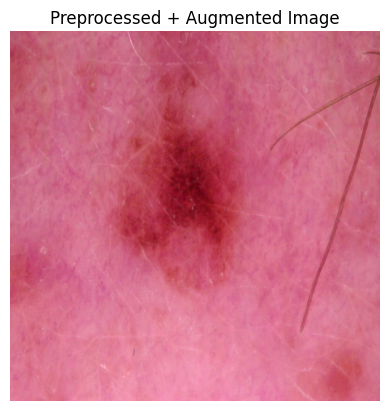

In [10]:
show_image(train_paths)

In [11]:
from tensorflow.keras import layers, models
import tensorflow as tf

def squeeze_excitation_block(input_tensor, ratio=16):
    filters = input_tensor.shape[-1]
    
    se = layers.GlobalAveragePooling2D()(input_tensor)
    se = layers.Dense(filters // ratio, activation="relu")(se)
    se = layers.Dense(filters, activation="sigmoid")(se)
    se = layers.Reshape((1, 1, filters))(se)
    
    return layers.Multiply()([input_tensor, se])

def build_model():
    base_model = tf.keras.applications.EfficientNetV2S(
        include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)
    )
    
    base_model.trainable = True
    for layer in base_model.layers[:int(len(base_model.layers) * 0.7)]:
        layer.trainable = False

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = base_model(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(2048, activation="mish")(x)
    x = layers.Dropout(0.4)(x)
    x = layers.LayerNormalization()(x)

    x = layers.Dense(1024, activation="mish")(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(512, activation="mish")(x)
    x = layers.Dropout(0.2)(x)

    outputs = layers.Dense(len(LABELS), activation="softmax")(x)

    model = models.Model(inputs, outputs)
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc"),
                 tf.keras.metrics.Precision(name="precision"),
                 tf.keras.metrics.Recall(name="recall")]
    )

    return model


In [12]:
model = build_model()

In [26]:
!pip install pydot graphviz


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: pip install --upgrade pip


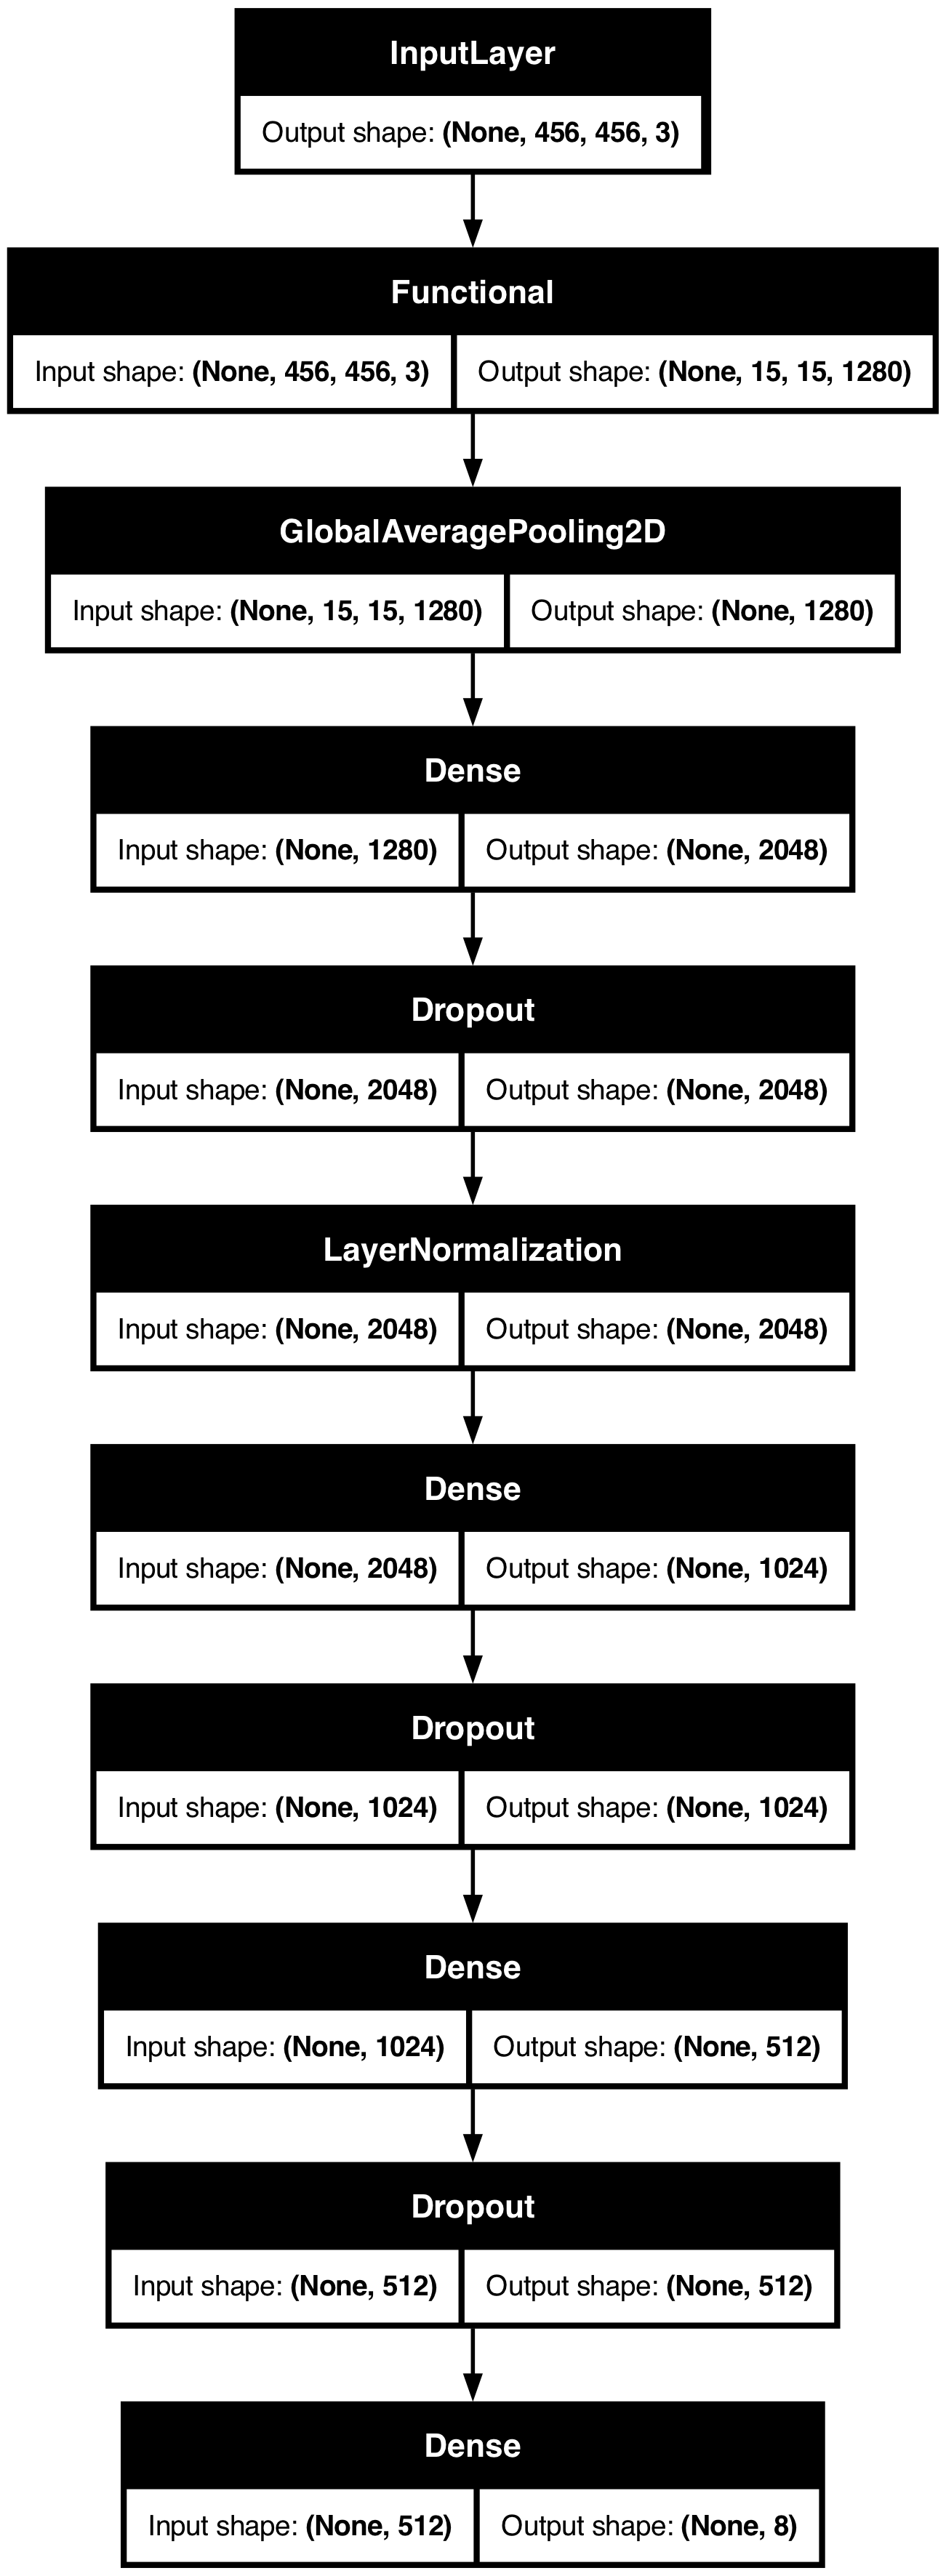

In [13]:
tf.keras.utils.plot_model(model, to_file='model-no-se.png', show_shapes=True)

In [14]:
train_labels_argmax = np.argmax(train_labels, axis=1)
class_weights = compute_class_weight(class_weight="balanced", classes=np.arange(len(LABELS)), y=train_labels_argmax)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}

In [15]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 15, 15, 1280)   │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │     2,623,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 2048)           │         4,096 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         4,104 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,586,024 (97.60 MB)

 Trainable params: 15,636,104 (59.65 MB)

 Non-trainable params: 9,949,920 (37.96 MB)

In [30]:
checkpoint = ModelCheckpoint(f"{MODEL_NAME}_baserun.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20


648/648 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3692 - auc: 0.7782 - loss: 1.8201 - precision: 0.4695 - recall: 0.2320
Epoch 1: val_accuracy improved from -inf to 0.55461, saving model to efficientnetv2-s-onehot-deep-unified-no-segm-no-se_baserun.keras
648/648 ━━━━━━━━━━━━━━━━━━━━ 996s 1s/step - accuracy: 0.3693 - auc: 0.7783 - loss: 1.8198 - precision: 0.4696 - recall: 0.2321 - val_accuracy: 0.5546 - val_auc: 0.8937 - val_loss: 1.3073 - val_precision: 0.6238 - val_recall: 0.5017 - learning_rate: 1.0000e-04
Epoch 2/20
648/648 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5399 - auc: 0.8884 - loss: 1.1624 - precision: 0.6254 - recall: 0.4425
Epoch 2: val_accuracy improved from 0.55461 to 0.60942, saving model to efficientnetv2-s-onehot-deep-unified-no-segm-no-se_baserun.keras
648/648 ━━━━━━━━━━━━━━━━━━━━ 885s 1s/step - accuracy: 0.5400 - auc: 0.8884 - loss: 1.1624 - precision: 0.6255 - recall: 0.4425 - val_accuracy: 0.6094 - val_auc: 0.9179 - val_loss: 1.1405 - val_precision: 0.65

In [16]:
model.load_weights(f"{MODEL_NAME}_baserun.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 288 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [17]:
def plot_history(history_dict):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Accuracy',
        'loss': 'Loss',
        'auc': 'Area Under Curve (AUC)',
        'precision': 'Precision',
        'recall': 'Recall'
    }

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label='Training Set')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label='Validation Set')
            plt.title(f'{metric_labels[metric]} over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()


In [22]:
def plot_history_ukr(history_dict, output_dir, model_name, lang_code='ukr'):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Точність',
        'loss': 'Втрата',
        'auc': 'Площа під кривою (AUC)',
        'precision': 'Влучність',
        'recall': 'Повнота'
    }

    os.makedirs(output_dir, exist_ok=True)

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label='Навчальний набір')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label='Валідаційний набір')
            plt.title(f'{metric_labels[metric]} протягом епох')
            plt.xlabel('Епохи')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()

            # Generate filename and save plot
            filename = f"{model_name}-{metric}-{lang_code}.png"
            filepath = os.path.join(output_dir, filename)
            plt.savefig(filepath)
            plt.close()


In [23]:
def plot_history(history_dict, output_dir, model_name, lang_code="eng"):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Accuracy',
        'loss': 'Loss',
        'auc': 'Area Under Curve (AUC)',
        'precision': 'Precision',
        'recall': 'Recall'
    }

    os.makedirs(output_dir, exist_ok=True)

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label='Training Set')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label='Validation Set')
            plt.title(f'{metric_labels[metric]} over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()

            # Generate filename and save plot
            filename = f"{model_name}-{metric}-{lang_code}.png"
            filepath = os.path.join(output_dir, filename)
            plt.savefig(filepath)
            plt.close()


In [24]:
from tqdm import tqdm
def confusion(model, ds):
  tf.keras.config.enable_unsafe_deserialization()
  # model.load_weights(f"{MODEL_NAME}_softmask_baserun_2.keras")
  # result = model.evaluate(ds)
  # print(result)
  y_true = np.argmax(np.concatenate([y.numpy() for _, y in tqdm(ds)]), axis=1)
  y_pred = np.argmax(model.predict(ds), axis=1)

  print(classification_report(y_true, y_pred, target_names=LABELS))

  conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
  plt.figure(figsize=(10, 8))
  sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
  plt.title("Confusion Matrix")
  plt.show()

def test_model(model, history, model_name, output_dir):
  print(history)
  plot_history(history, output_dir, model_name)
  plot_history_ukr(history, output_dir, model_name)
  train_eval_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
  train_eval_dataset = train_eval_dataset.map(preprocess_and_augment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

  for dataset, label in zip([train_eval_dataset, val_dataset, test_dataset], ['train', 'val', 'test']):
    print(f"#####  {label}  #####")
    confusion(model, dataset)


In [ ]:
# model = build_model()
# model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/notebooks/efficientnetv2-s-onehot-deep-unified-no-segm-no-se_baserun.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 288 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [20]:
import json
TRAIN_RESULT_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-s-no-se-20.json"

with open(TRAIN_RESULT_PATH) as f:
    history = json.loads(f.read())

{'accuracy': [0.3692, 0.5399, 0.5869, 0.6309, 0.6706, 0.6816, 0.703, 0.7251, 0.7364, 0.7562, 0.7659, 0.7865, 0.7793, 0.8062, 0.8203, 0.8421, 0.8517, 0.862, 0.8631, 0.8661], 'auc': [0.7782, 0.8884, 0.9156, 0.9307, 0.9442, 0.9502, 0.9544, 0.9615, 0.9609, 0.9688, 0.9709, 0.9748, 0.9742, 0.9794, 0.9827, 0.9856, 0.9877, 0.9892, 0.9891, 0.9886], 'loss': [1.8201, 1.1624, 0.9668, 0.8105, 0.7211, 0.6441, 0.605, 0.5483, 0.5125, 0.4518, 0.4552, 0.3804, 0.4188, 0.3265, 0.2897, 0.244, 0.2423, 0.2078, 0.2184, 0.1989], 'precision': [0.4695, 0.6254, 0.658, 0.6926, 0.7213, 0.7348, 0.7454, 0.7646, 0.7712, 0.7884, 0.7947, 0.812, 0.8048, 0.8296, 0.839, 0.8559, 0.8657, 0.8751, 0.8769, 0.878], 'recall': [0.232, 0.4425, 0.5073, 0.5617, 0.6097, 0.632, 0.657, 0.6842, 0.6964, 0.7227, 0.7371, 0.7594, 0.751, 0.7866, 0.7996, 0.8265, 0.8367, 0.8512, 0.851, 0.8535], 'val_accuracy': [0.5546, 0.6094, 0.6584, 0.6704, 0.6924, 0.6851, 0.714, 0.7044, 0.7414, 0.7399, 0.7692, 0.7333, 0.7773, 0.7723, 0.7908, 0.792, 0.8016, 0

100%|██████████| 648/648 [04:18<00:00,  2.51it/s]
2025-05-17 13:32:41.843844: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


648/648 ━━━━━━━━━━━━━━━━━━━━ 663s 1s/step
              precision    recall  f1-score   support

         MEL       0.83      0.93      0.87      4085
          NV       0.98      0.88      0.93     10300
         BCC       0.94      0.98      0.96      2659
          AK       0.93      1.00      0.96       694
         BKL       0.90      0.99      0.94      2099
          DF       0.87      1.00      0.93       191
        VASC       0.78      1.00      0.88       202
         SCC       0.96      1.00      0.98       502

    accuracy                           0.92     20732
   macro avg       0.90      0.97      0.93     20732
weighted avg       0.93      0.92      0.92     20732



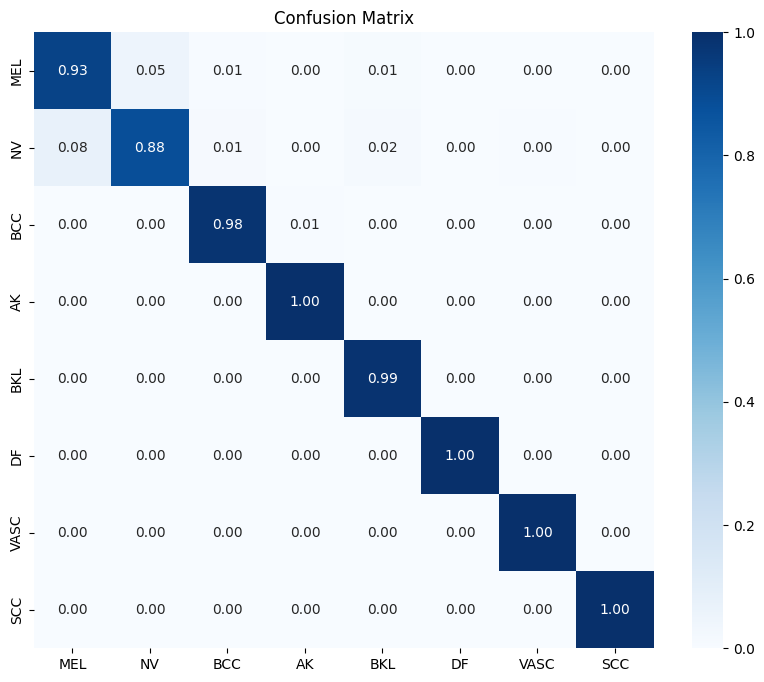

#####  val  #####


100%|██████████| 81/81 [00:04<00:00, 18.94it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step
              precision    recall  f1-score   support

         MEL       0.70      0.77      0.73       510
          NV       0.92      0.83      0.87      1287
         BCC       0.85      0.85      0.85       332
          AK       0.63      0.74      0.68        87
         BKL       0.68      0.75      0.71       262
          DF       0.50      0.62      0.56        24
        VASC       0.76      1.00      0.87        26
         SCC       0.61      0.68      0.64        63

    accuracy                           0.81      2591
   macro avg       0.71      0.78      0.74      2591
weighted avg       0.82      0.81      0.81      2591



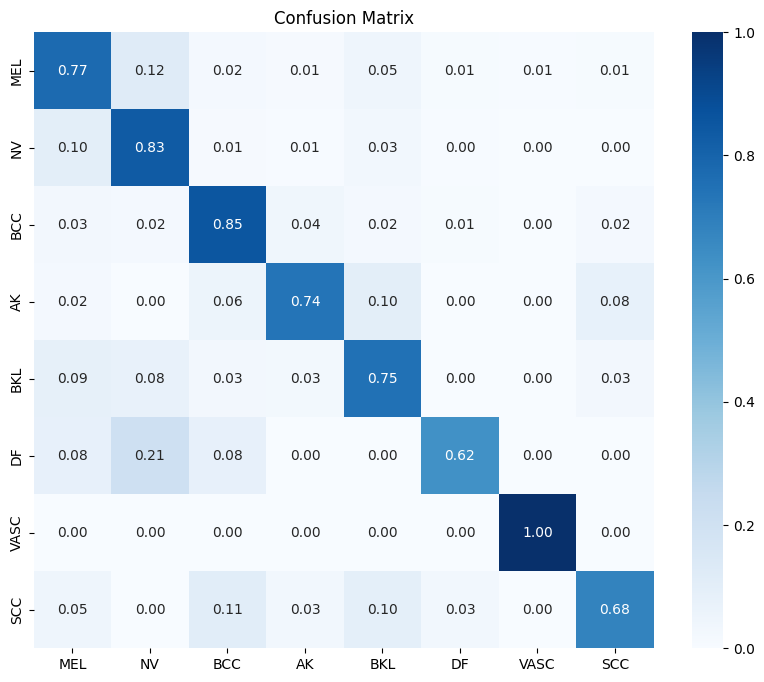

#####  test  #####


100%|██████████| 81/81 [00:04<00:00, 18.38it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 82s 994ms/step
              precision    recall  f1-score   support

         MEL       0.68      0.77      0.72       511
          NV       0.91      0.82      0.86      1288
         BCC       0.84      0.87      0.86       332
          AK       0.61      0.69      0.64        86
         BKL       0.75      0.79      0.77       263
          DF       0.55      0.88      0.68        24
        VASC       0.62      0.92      0.74        25
         SCC       0.68      0.75      0.71        63

    accuracy                           0.81      2592
   macro avg       0.71      0.81      0.75      2592
weighted avg       0.82      0.81      0.81      2592



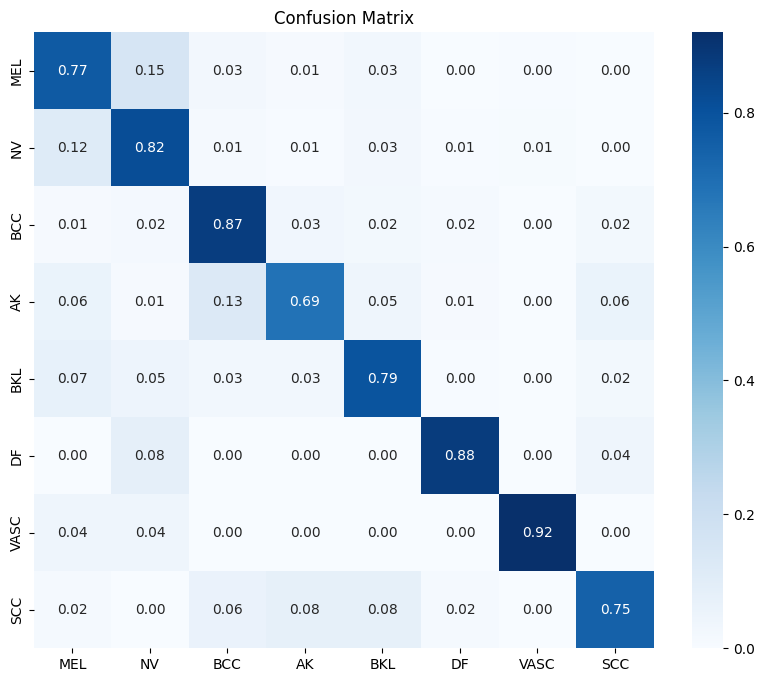

In [25]:
test_model(model, history, 'efficientnetv2-s-no-segm-no-se', "/Users/mac/Development/diploma/skin-mutation-detection/models/results/efficientnetv2-no-segm-no-se")

#####  train  #####


100%|██████████| 648/648 [03:29<00:00,  3.09it/s]


648/648 ━━━━━━━━━━━━━━━━━━━━ 817s 1s/step
              precision    recall  f1-score   support

         MEL       0.82      0.93      0.87      4085
          NV       0.98      0.88      0.93     10300
         BCC       0.95      0.98      0.97      2659
          AK       0.93      1.00      0.96       694
         BKL       0.90      0.99      0.94      2099
          DF       0.88      1.00      0.94       191
        VASC       0.81      1.00      0.89       202
         SCC       0.96      1.00      0.98       502

    accuracy                           0.92     20732
   macro avg       0.90      0.97      0.93     20732
weighted avg       0.93      0.92      0.92     20732



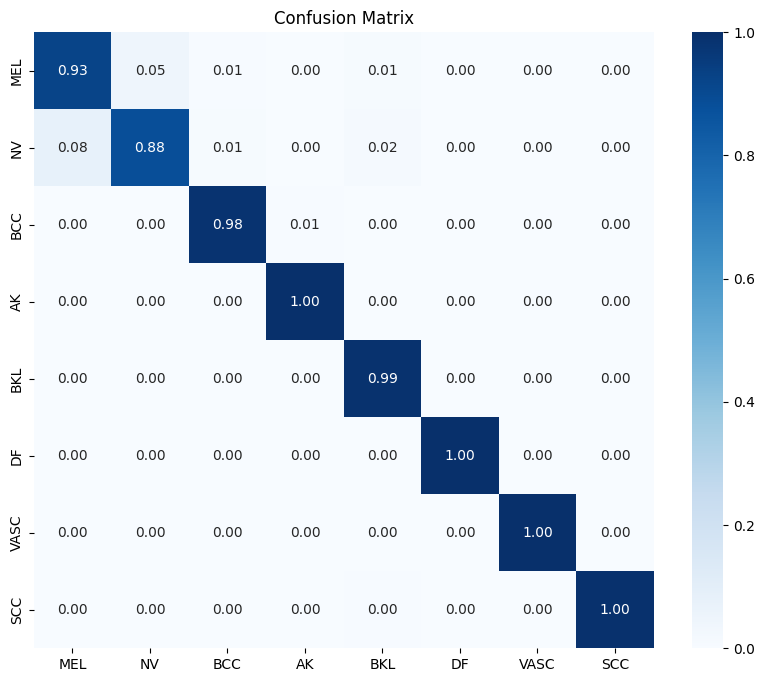

#####  val  #####


100%|██████████| 81/81 [00:04<00:00, 18.58it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 82s 997ms/step
              precision    recall  f1-score   support

         MEL       0.70      0.77      0.73       510
          NV       0.92      0.83      0.87      1287
         BCC       0.85      0.85      0.85       332
          AK       0.63      0.74      0.68        87
         BKL       0.68      0.75      0.71       262
          DF       0.50      0.62      0.56        24
        VASC       0.76      1.00      0.87        26
         SCC       0.61      0.68      0.64        63

    accuracy                           0.81      2591
   macro avg       0.71      0.78      0.74      2591
weighted avg       0.82      0.81      0.81      2591



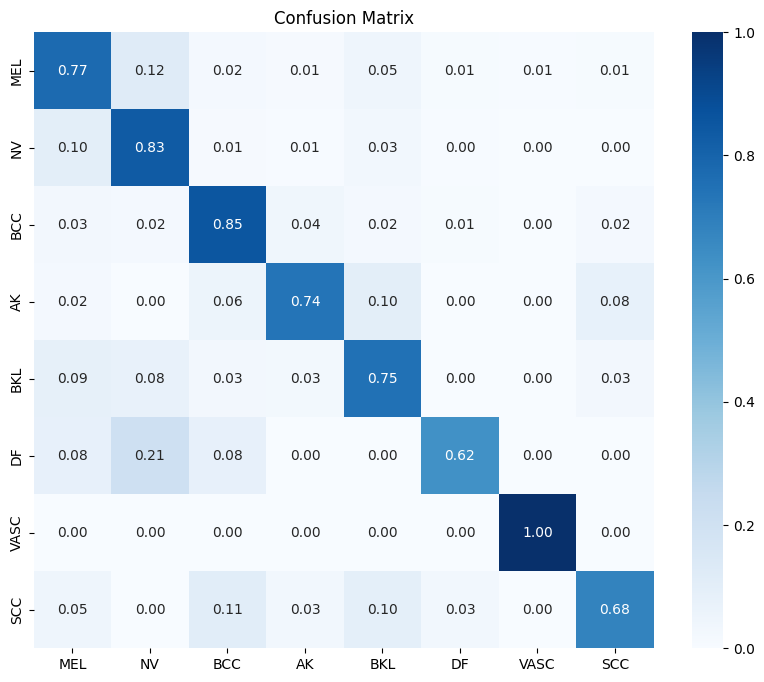

#####  test  #####


100%|██████████| 81/81 [00:03<00:00, 25.76it/s]


81/81 ━━━━━━━━━━━━━━━━━━━━ 54s 658ms/step
              precision    recall  f1-score   support

         MEL       0.68      0.77      0.72       511
          NV       0.91      0.82      0.86      1288
         BCC       0.84      0.87      0.86       332
          AK       0.61      0.69      0.64        86
         BKL       0.75      0.79      0.77       263
          DF       0.55      0.88      0.68        24
        VASC       0.62      0.92      0.74        25
         SCC       0.68      0.75      0.71        63

    accuracy                           0.81      2592
   macro avg       0.71      0.81      0.75      2592
weighted avg       0.82      0.81      0.81      2592



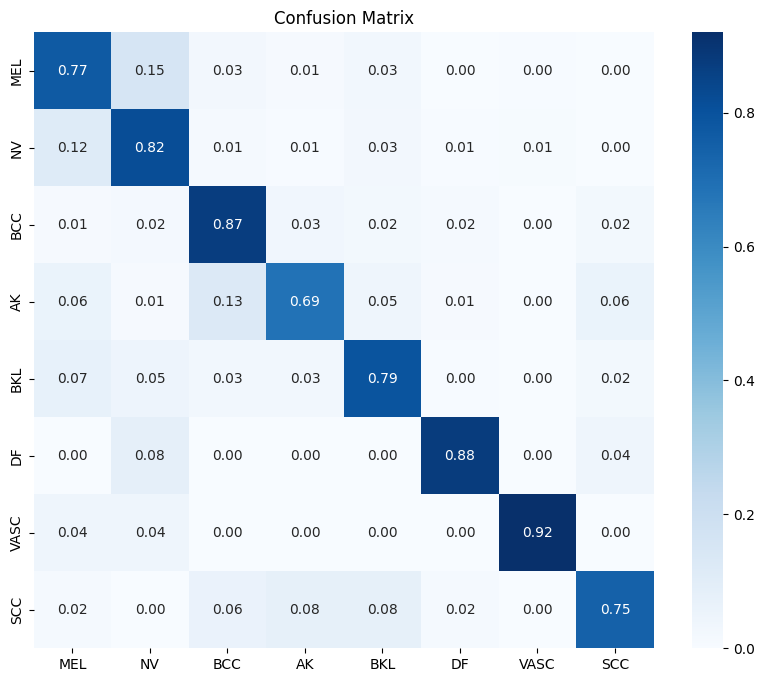

In [36]:
train_eval_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_eval_dataset = train_eval_dataset.map(preprocess_and_augment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

for dataset, label in zip([train_eval_dataset, val_dataset, test_dataset], ['train', 'val', 'test']):
    print(f"#####  {label}  #####")
    confusion(model, dataset)